# 02. Baseline: TF-IDF + Logistic Regression

Task: given a Python snippet, predict whether it is **buggy** (label 1) or **fixed** (label 0).

Baseline idea: turn each snippet into a vector of word/symbol counts (TF-IDF) and train a linear classifier on top.
It is simple and fast, and it gives a reference number that every later model (BiLSTM, LLM) has to beat.
We measure accuracy, precision, recall and F1 on the **validation** set. The test set stays untouched until the end.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

sys.path.append("../src")
import data_utils as du

PROCESSED = Path("../data/processed/small")  # the small tier, see 01_data.ipynb
SEED = 42

## Step 1. Load the splits and build labelled examples

We use the **small** tier (`data/processed/small/`): this baseline runs on CPU in minutes.

Every pair gives two examples: the buggy code (label 1) and the fixed code (label 0).
So 4000 train pairs become 8000 training examples and 500 val pairs become 1000 validation examples.
The classes are balanced by construction, so a model that guesses randomly gets about 50% accuracy.

In [2]:
train_pairs = pd.read_parquet(PROCESSED / "train.parquet")
val_pairs = pd.read_parquet(PROCESSED / "val.parquet")

train = du.pairs_to_examples(train_pairs)
val = du.pairs_to_examples(val_pairs)
print("train examples:", len(train), "| val examples:", len(val))
print(train["label"].value_counts().to_dict())
train.head(4)

train examples: 8000 | val examples: 1000
{1: 4000, 0: 4000}


,pair,text,label
0,0,"\n @classmethod\n def from_artifact(cls,...",1
1,1,"lf.write(""{}\n"".format(self.__str_...",1
2,2,"\n except ( web.DownloadError, web.NotF...",1
3,3,active = i\n i+=1 ...,1


## Step 2. TF-IDF features

TF-IDF counts how often each token appears in a snippet and down-weights tokens that appear in almost every snippet
(like `self` or `=`). Choices:

* **Code-aware tokens:** we split into identifiers, numbers and single symbols (`(`, `.`, `==`...), because for code
  the punctuation matters. The default tokenizer would throw it away.
* **1- and 2-grams:** pairs of neighbouring tokens catch small patterns like `== None` or `) :`.
* **`min_df=2`:** ignore tokens seen in only one snippet (rare names add noise).
* **Fit on train only:** the vocabulary and weights are learned from train; val is only transformed.
  Fitting on val would leak information about the validation set.

In [3]:
vectorizer = TfidfVectorizer(
    token_pattern=r"[A-Za-z_]\w*|\d+|[^\s\w]",
    lowercase=False,
    ngram_range=(1, 2),
    min_df=2,
)
X_train = vectorizer.fit_transform(train["text"])
X_val = vectorizer.transform(val["text"])
print("features:", X_train.shape[1])

features: 107270


## Step 3. Train Logistic Regression

Logistic Regression learns one weight per feature; a positive weight pushes the prediction towards "buggy".
It is a linear model, so we can read the weights and see what it learned.

In [4]:
model = LogisticRegression(max_iter=1000, random_state=SEED)
model.fit(X_train, train["label"])
print("trained")

trained


## Step 4. Metrics on the validation set

* **Accuracy:** share of correct predictions.
* **Precision:** of the snippets we call buggy, how many really are.
* **Recall:** of the really buggy snippets, how many we find.
* **F1:** the harmonic mean of precision and recall.

accuracy   0.523
precision  0.533
recall     0.368
f1         0.436
train accuracy 0.571


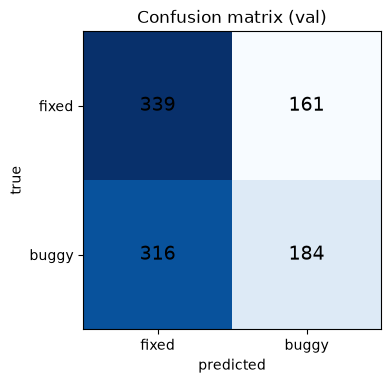

In [5]:
y_true = val["label"].to_numpy()
y_pred = model.predict(X_val)

metrics = {
    "accuracy": accuracy_score(y_true, y_pred),
    "precision": precision_score(y_true, y_pred),
    "recall": recall_score(y_true, y_pred),
    "f1": f1_score(y_true, y_pred),
}
for name, value in metrics.items():
    print(f"{name:10s} {value:.3f}")

# sanity check: how well does the model fit the data it has seen?
train_accuracy = accuracy_score(train["label"], model.predict(X_train))
print(f"train accuracy {train_accuracy:.3f}")

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax.set_xticks([0, 1], ["fixed", "buggy"])
ax.set_yticks([0, 1], ["fixed", "buggy"])
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title("Confusion matrix (val)")
fig.tight_layout()
fig.savefig("../results/figures/baseline_confusion.png", dpi=150)
plt.show()

## Step 5. Pair-level check

The buggy and fixed snippets of one pair are almost identical (they differ by one statement), so a more telling
question is: for the **same pair**, does the model give the buggy version a higher "buggy" probability than the fixed one?
If it does not, the model cannot tell them apart even when both are shown side by side.

In [6]:
val = val.assign(p_buggy=model.predict_proba(X_val)[:, 1])
by_pair = val.pivot(index="pair", columns="label", values="p_buggy")  # columns: 0 = fixed, 1 = buggy
pair_accuracy = float((by_pair[1] > by_pair[0]).mean())
tie_share = float((by_pair[1] == by_pair[0]).mean())
print(f"pairs where buggy gets a higher score than fixed: {pair_accuracy:.3f}")
print(f"pairs with identical scores (same tokens): {tie_share:.3f}")

pairs where buggy gets a higher score than fixed: 0.552
pairs with identical scores (same tokens): 0.088


## Step 6. What did the model learn?

The largest positive weights are the tokens that most push a prediction towards "buggy",
the largest negative ones towards "fixed".

In [7]:
features = np.array(vectorizer.get_feature_names_out())
order = np.argsort(model.coef_[0])
print("towards FIXED:", list(features[order[:15]]))
print("towards BUGGY:", list(features[order[::-1][:15]]))

towards FIXED:

 ['and', 'or', 'int (', "8 '", 'str (', 'False )', 'None', "' utf", 'None )', 'str', 'False', ') )', 'int', '8', ') .']
towards BUGGY: ['( )', '255', ': pass', ':', 'if not', 'id ,', '3', 'pass', 'return str', 'True @', 'log', '( (', '( "', 'res', 'return super']


## Save the results

In [8]:
results = {k: round(float(v), 4) for k, v in metrics.items()}
results["pair_accuracy"] = round(pair_accuracy, 4)
results["pairs_with_identical_scores"] = round(tie_share, 4)
results["train_accuracy"] = round(float(train_accuracy), 4)
results["n_features"] = int(X_train.shape[1])
Path("../results/baseline_metrics.json").write_text(json.dumps(results, indent=2))
results

{'accuracy': 0.523,
 'precision': 0.5333,
 'recall': 0.368,
 'f1': 0.4355,
 'pair_accuracy': 0.552,
 'pairs_with_identical_scores': 0.088,
 'train_accuracy': 0.5709,
 'n_features': 107270}

## Conclusion

Numbers from the run above on the **small** tier (4000 train / 500 val pairs), also saved in `results/baseline_metrics.json`.

| Metric | Value |
|---|---|
| Accuracy (val) | 0.523 |
| Precision (val) | 0.533 |
| Recall (val) | 0.368 |
| F1 (val) | 0.436 |
| Pair-level accuracy (val) | 0.552 |
| Accuracy (train) | 0.571 |

**The baseline is close to random guessing** (50% on balanced classes). This is a real result, not a bug:

* **0.523 on 1000 val examples is within noise of 50%.** With 1000 examples, pure guessing lands anywhere in roughly 47-53% (95% range), so this number does not show a real signal.
* **Train accuracy is also low (0.57).** The model is not overfitting; it simply cannot separate the classes even on data it has seen.
* **Why:** the buggy and fixed snippets of a pair share almost all of their tokens (the same context lines), but have opposite labels.
  A bag of tokens sees nearly the same input twice with two different answers. The difference is one statement, which TF-IDF dilutes among dozens of unchanged tokens.
* **8.8% of pairs get exactly the same score:** their tokens are identical for the vectorizer (for example, fixes that only change indentation or the contents of a string), so no bag-of-tokens model can separate them.
* **The "important" tokens look like noise:** `and`, `or`, `int (` and `str (` for fixed versus `( )`, `255`, `: pass` and `if not` for buggy reflect habits of a few projects, not a general bug signal.
* **Precision 0.53 with recall 0.37:** the model says "buggy" less often than "fixed" and is right about as often as a coin flip.

The previous sample (before the two tiers were introduced) gave val accuracy 0.503; the new small tier is a different random draw, and both numbers are near chance.

**What this means for the next steps:** the signal is in the *order and structure* of tokens and in the meaning of the changed statement, not in which tokens occur.
Models that read code in sequence (BiLSTM) or have seen a lot of code (a pretrained code LLM, possibly fine-tuned with LoRA) are the natural next step, and this number is the reference they must beat.